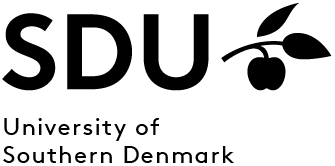
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

## Morphological filtering: opening, closing and line removal

In [1]:
import numpy as np
from scipy import ndimage as ndi

try:
    import oip
except Exception:
    oip = None

from oip import show_image, show_images

White means foreground (`True`). All footprints below are centred and odd-sized. SciPy treats pixels outside the image as background. The input examples leave a margin at the boundary.

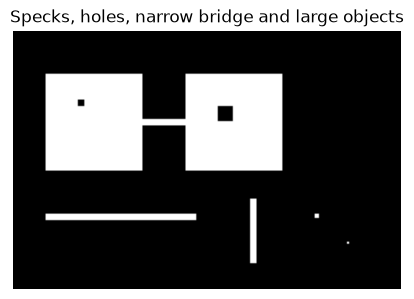

In [2]:
mask = oip.week05.morphology_mask()
oip.show_image(mask, "Specks, holes, narrow bridge and large objects", vmin=0, vmax=1);

## Activity — Choose–Predict–Test–Compare

In pairs, choose an operation and structuring element for **one** goal:

- remove small foreground specks,
- fill small holes, or
- preserve an object while removing a directional artefact.

**Choose:** agree on an operation and structuring element.  
**Predict:** state what else you expect to change.  
**Test:** run the cells below and vary the footprint.  
**Compare:** identify one improvement and one lost or altered structure.

If time allows, reproduce one result in FIJI. Check foreground polarity,
structuring-element geometry and border handling before interpreting a
difference as an error.

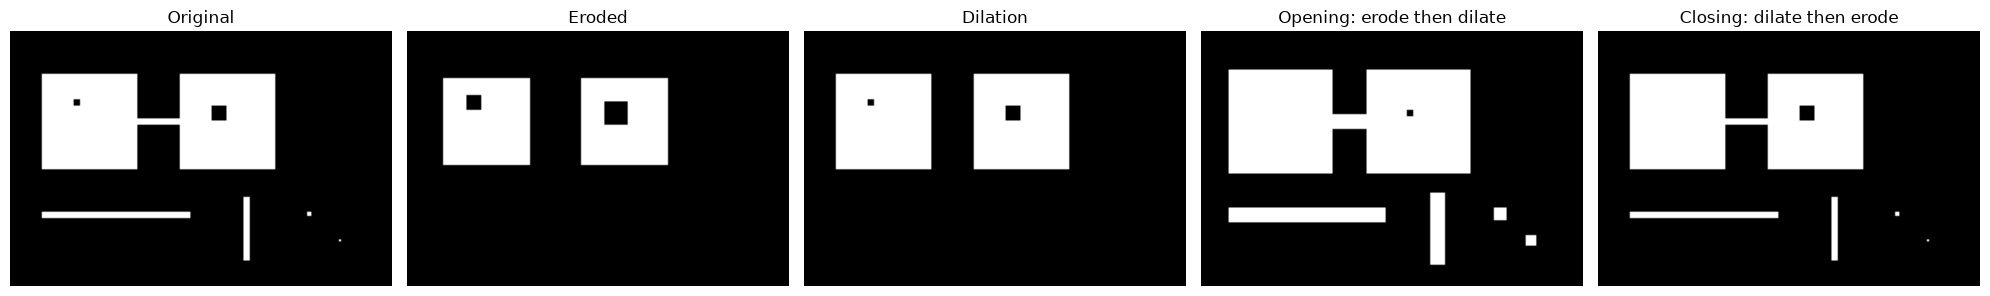

In [11]:
size = 5
footprint = np.ones((size, size), dtype=bool)

# Lecture fill-in (about 1 min): opening = erosion followed by dilation
# with the same structuring element.
eroded = ndi.binary_erosion(mask,structure=footprint)
opened = ndi.binary_dilation(eroded,structure=footprint)

# Closing is shown for comparison.
dilated = ndi.binary_dilation(mask, structure=footprint)
closed = ndi.binary_erosion(dilated, structure=footprint)

show_images(
    mask, eroded, opened, dilated, closed,
    titles=["Original", "Eroded", "Dilation", "Opening: erode then dilate",
            "Closing: dilate then erode"],
    vmin=0, vmax=1,
);


### Interactive demo — operation, size and footprint shape

After the fill-in, explore the same mask interactively. Choose a goal first
(remove specks, fill holes, or preserve a narrow bridge), predict a useful
operation/footprint, and then test it.

In [12]:
from ipywidgets import Dropdown, IntSlider, interact
from skimage.morphology import disk

def morphology_demo(operation="opening", size=3, shape="square"):
    if shape == "square":
        demo_footprint = np.ones((size, size), dtype=bool)
    else:
        demo_footprint = disk(size // 2)

    operations = {
        "erosion": ndi.binary_erosion,
        "dilation": ndi.binary_dilation,
        "opening": ndi.binary_opening,
        "closing": ndi.binary_closing,
    }
    result = operations[operation](
        mask,
        structure=demo_footprint,
    )

    show_images(
        mask,
        demo_footprint,
        result,
        titles=[
            "Input",
            f"{shape} footprint",
            f"{operation}, size={size}",
        ],
        vmin=0,
        vmax=1,
    )

interact(
    morphology_demo,
    operation=Dropdown(
        options=["erosion", "dilation", "opening", "closing"],
        value="opening",
        description="operation",
    ),
    size=IntSlider(
        value=3, min=1, max=11, step=2,
        description="size",
    ),
    shape=Dropdown(
        options=["square", "disk"],
        value="square",
        description="shape",
    ),
);

interactive(children=(Dropdown(description='operation', index=2, options=('erosion', 'dilation', 'opening', 'c…

### Discuss after running
Opening removes specks and the narrow foreground bridge, separating the two blocks. Closing fills the small hole; a larger footprint can also fill larger holes or join nearby objects. Losing a bridge is harmful if it represents a real connection. Neither operation generally restores the original geometry.

## Test and compare footprint size

Compare a small and a larger centred square. Keep the operation fixed so that
you change only the footprint size.

After running the next cell, discuss with a partner:

- Which desired structure was preserved or removed?
- Which unintended structure changed?
- Does this support your prediction from the activity above?

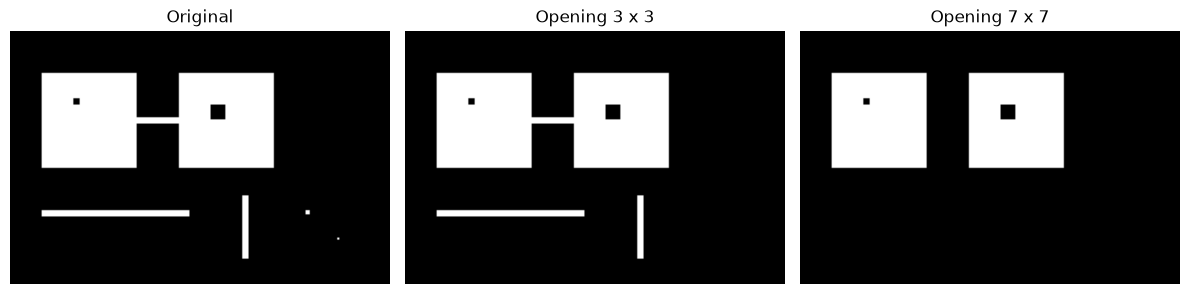

In [13]:
small = ndi.binary_opening(mask, structure=np.ones((3, 3)))
large = ndi.binary_opening(mask, structure=np.ones((7, 7)))
show_images(mask, small, large,
            titles=["Original", "Opening 3 x 3", "Opening 7 x 7"], vmin=0, vmax=1);

### Discuss after running
The small opening removes isolated specks while retaining the three-pixel-wide bridge and bars. The larger opening removes those narrow structures too. State the footprint and polarity when sharing results. Repeating an identical opening is idempotent; enlarging the footprint changes the operation.

### Reuse: original opening and closing TIFFs
These two old masks have **bright** foreground. They are small enough to inspect individual pixels.

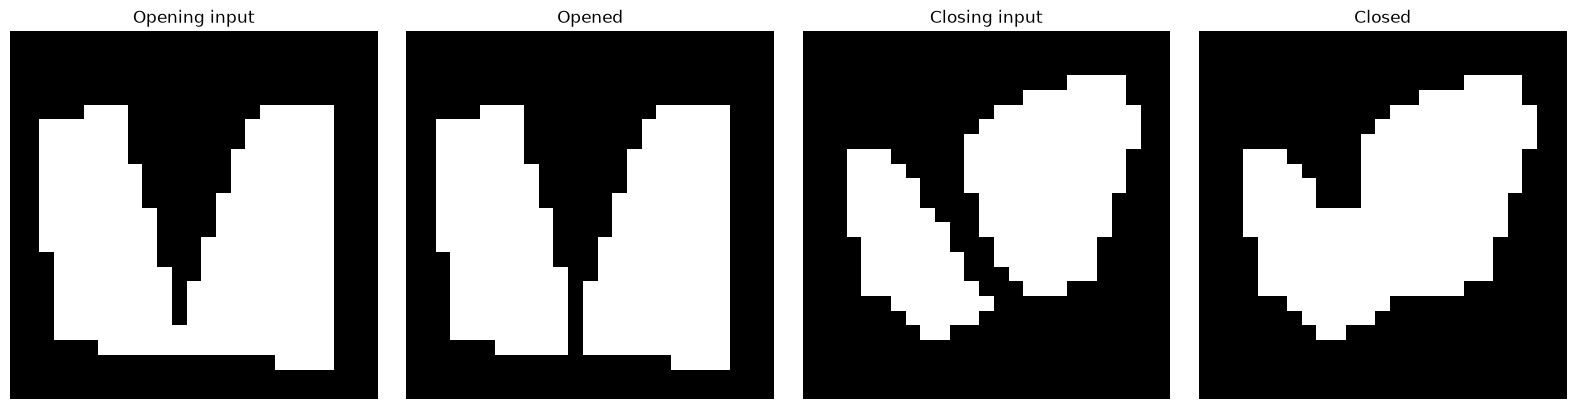

In [15]:
old_open = oip.week05.load_mask("img/opening-example-3.tif")
old_close = oip.week05.load_mask("img/closing-example-1.tif")
opened = ndi.binary_opening(old_open, structure=np.ones((3, 3)))
closed = ndi.binary_closing(old_close, structure=np.ones((3, 3)))
show_images(old_open, opened, old_close, closed,
            titles=["Opening input", "Opened", "Closing input", "Closed"],
            vmin=0, vmax=1);

## M3 — Directional line removal (extension to the lecture)
The original `l07.ipynb` asked students to **keep** horizontal or vertical lines. Here we first extract them, then remove them from the original. The TIFF has **dark** foreground and slightly tilted lines.

**Think:** Which footprint preserves horizontal structures? How do we remove the extracted structures?

**Pair:** Choose a length longer than the circles’ diameter but shorter than the long lines.

**Share:** Explain what will happen at intersections and for tilted or short lines.

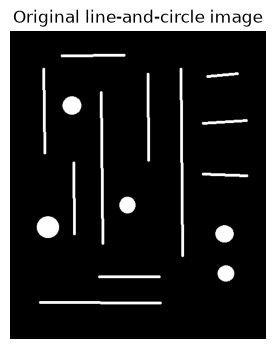

In [16]:
lines = oip.week05.load_mask("img/erosion-example-1.tif", dark_foreground=True)
show_image(lines, "Original line-and-circle image", vmin=0, vmax=1);

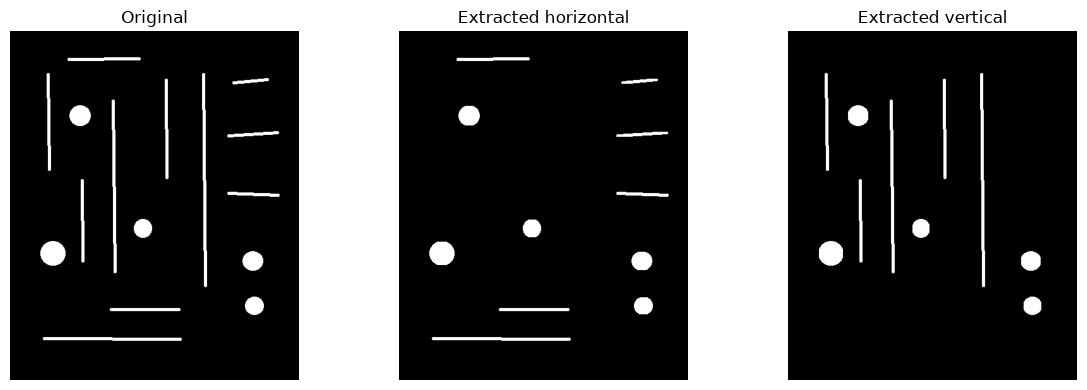

In [19]:
length = 11
horizontal_footprint = np.ones((1, length), dtype=bool)
vertical_footprint = np.ones((length, 1), dtype=bool)

horizontal = ndi.binary_opening(lines, structure=horizontal_footprint)
vertical = ndi.binary_opening(lines, structure=vertical_footprint)
show_images(lines, horizontal, vertical,
            titles=["Original", "Extracted horizontal", "Extracted vertical"], vmin=0, vmax=1);

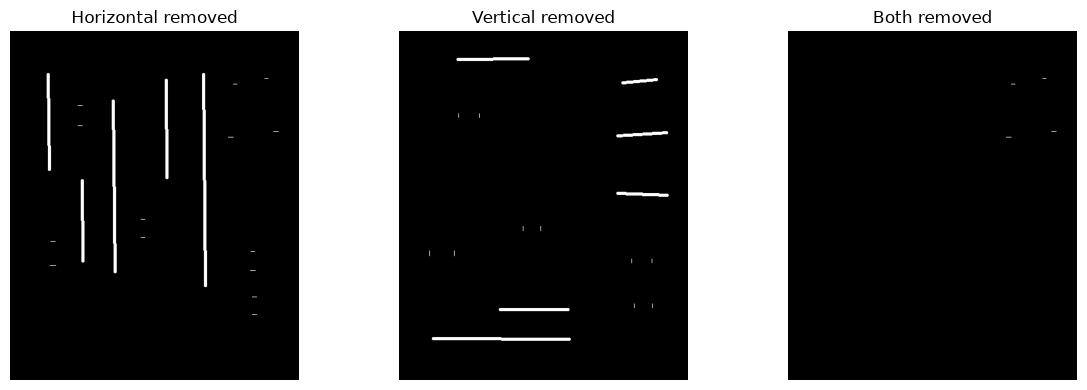

In [20]:
# & means AND, | means OR, and ~ means NOT for these Boolean masks.
no_horizontal = lines & ~horizontal
no_vertical = lines & ~vertical
no_lines = lines & ~(horizontal | vertical)
show_images(no_horizontal, no_vertical, no_lines,
            titles=["Horizontal removed", "Vertical removed", "Both removed"],
            vmin=0, vmax=1);

### Discuss after running
A horizontal footprint retains sufficiently long horizontal runs; a vertical footprint retains vertical runs. Opening extracts them; Boolean masking removes them. Short or tilted lines can leave fragments, and shared pixels at crossings may be removed from objects you wanted to keep. This old image deliberately makes those limitations visible. Try lengths 31, 51 and 71; report one circle preserved and one line fragment remaining.

### Optional: isolate circles as in the old notebook
A small square opening removes thin lines while preserving the larger filled circles. This may achieve the desired result more cleanly than subtracting axis-aligned lines; it still changes object boundaries.

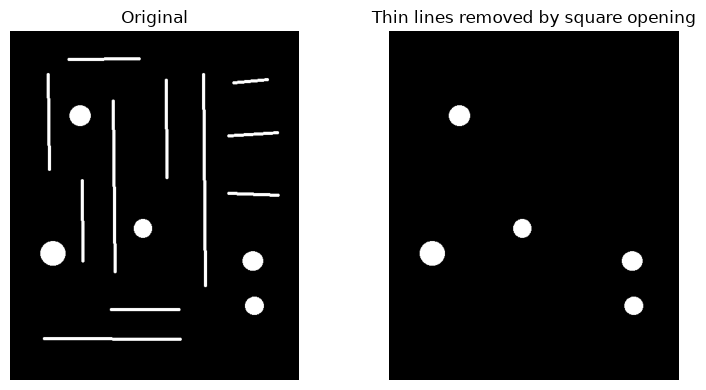

In [21]:
circles = ndi.binary_opening(lines, structure=np.ones((7, 7)))
show_images(lines, circles, titles=["Original", "Thin lines removed by square opening"],
            vmin=0, vmax=1);

### Exit question — same as the lecture
For a noisy binary marker image, propose a sequence of operations to find its outer corners. Explain one reason morphological filtering might help and one reason it might damage the result.

**Discuss:** Conservative mask cleanup → boundary extraction → Hough lines → intersections is one option. Harris is another local approach. Cleanup can remove spurious features but can also round corners, displace boundaries or erase thin structures. This is a design question, not a claim that the line-and-circle image is a marker.

## Optional programming challenge

Interested in the actual implementation? Continue with
[`l05-6_optional_programming.ipynb`](l05-6_optional_programming.ipynb).
The optional notebook follows the Burger & Burge algorithm structure and keeps
the implementation-focused, scored exercises separate from the lecture demo.

## Assignment — design a morphology pipeline

Work in pairs or groups of three.

1. Use your own binary image if possible; otherwise use one of the provided
   masks.
2. Define a concrete goal: for example remove specks, fill holes, disconnect
   an unwanted bridge, or remove a directional artefact.
3. Design a sequence of morphological operations and justify each structuring
   element.
4. Compare at least **two footprint sizes or shapes**.
5. Reproduce the final pipeline in FIJI if possible. Check foreground polarity,
   structuring-element geometry and border handling before comparing results.
6. Record one case where the implementations agree and one apparent
   disagreement.
7. Optionally ask an LLM to critique the pipeline; accept only suggestions
   that survive an experimental check.

**Submit:** original mask, final result, operation sequence and short
justification.

### Share something interesting on Itslearning

This week, **sharing examples and results is encouraged**. Morphological
operations often produce very visual examples, so post an interesting result
to the Week 05 Itslearning submission if you find one.

Examples worth sharing:

- an own binary image where one simple operation solves a real cleanup problem;
- two footprints with similar size but clearly different effects;
- an opening/closing step that removes the intended feature but also damages
  something important;
- a directional structuring element that isolates a useful feature;
- a Python/FIJI difference caused by polarity, footprint geometry or border
  handling;
- an LLM-proposed pipeline that you improved after testing it.

A useful post can be **before/after images + the operation and structuring
element + 2–4 sentences explaining the trade-off**. Pair/group examples are
welcome.
